# Model comparison

The comparison table is an artifact view, not a place to type metrics. It reads `reports/results/model_comparison.csv` (created by the gated report stage), grouped-CV rows, and efficiency records. Missing final artifacts remain visibly missing.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / 'reports').exists(): ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'scripts'))
from generate_report import _test_gate_diagnostics
gate_diagnostics = _test_gate_diagnostics(ROOT)
if gate_diagnostics: raise RuntimeError('TEST comparison gate is invalid: ' + '; '.join(gate_diagnostics))
comparison_path = ROOT / 'reports' / 'results' / 'model_comparison.csv'
if comparison_path.exists():
    comparison = pd.read_csv(comparison_path)
    display(comparison)
else:
    comparison = pd.DataFrame()
    print('Final comparison table is pending. Run the gated report stage after TEST evaluation.')

,family,model,pretrained,parameters,best_epoch,val_accuracy,test_accuracy,test_macro_f1,test_weighted_f1,cv_macro_f1_mean,cv_macro_f1_std,train_accuracy,train_macro_f1,accuracy_gap,macro_f1_gap,inference_ms_per_image,model_size_mb,training_time_seconds,overfitting_indicator
0,baseline CNN,custom_cnn,False,3389287,3,0.614286,0.497619,0.490151,0.490151,NaN,NaN,0.668398,0.656758,0.054113,0.044848,1.377418,38.853007,396.277478,not_flagged
1,residual CNN,resnet50,True,23522375,7,0.842857,0.697619,0.682893,0.682893,0.717181,0.109449,0.999567,0.999567,0.156710,0.166567,6.443244,269.631427,557.305221,potential_overfitting
2,modern CNN,convnext_tiny,True,27825511,15,0.857143,0.611905,0.569016,0.569016,0.787366,0.112978,1.000000,1.000000,0.142857,0.152381,6.488600,318.655147,904.605523,not_flagged
3,vision transformer,vit_b16,True,85804039,19,0.830952,0.600000,0.562363,0.562363,0.744863,0.103026,0.999134,0.999134,0.168182,0.174597,7.297118,982.137385,1511.294948,not_flagged


,cv_macro_f1_mean,cv_macro_f1_std
model,,
convnext_tiny,0.787,0.113
resnet50,0.717,0.109
vit_b16,0.745,0.103


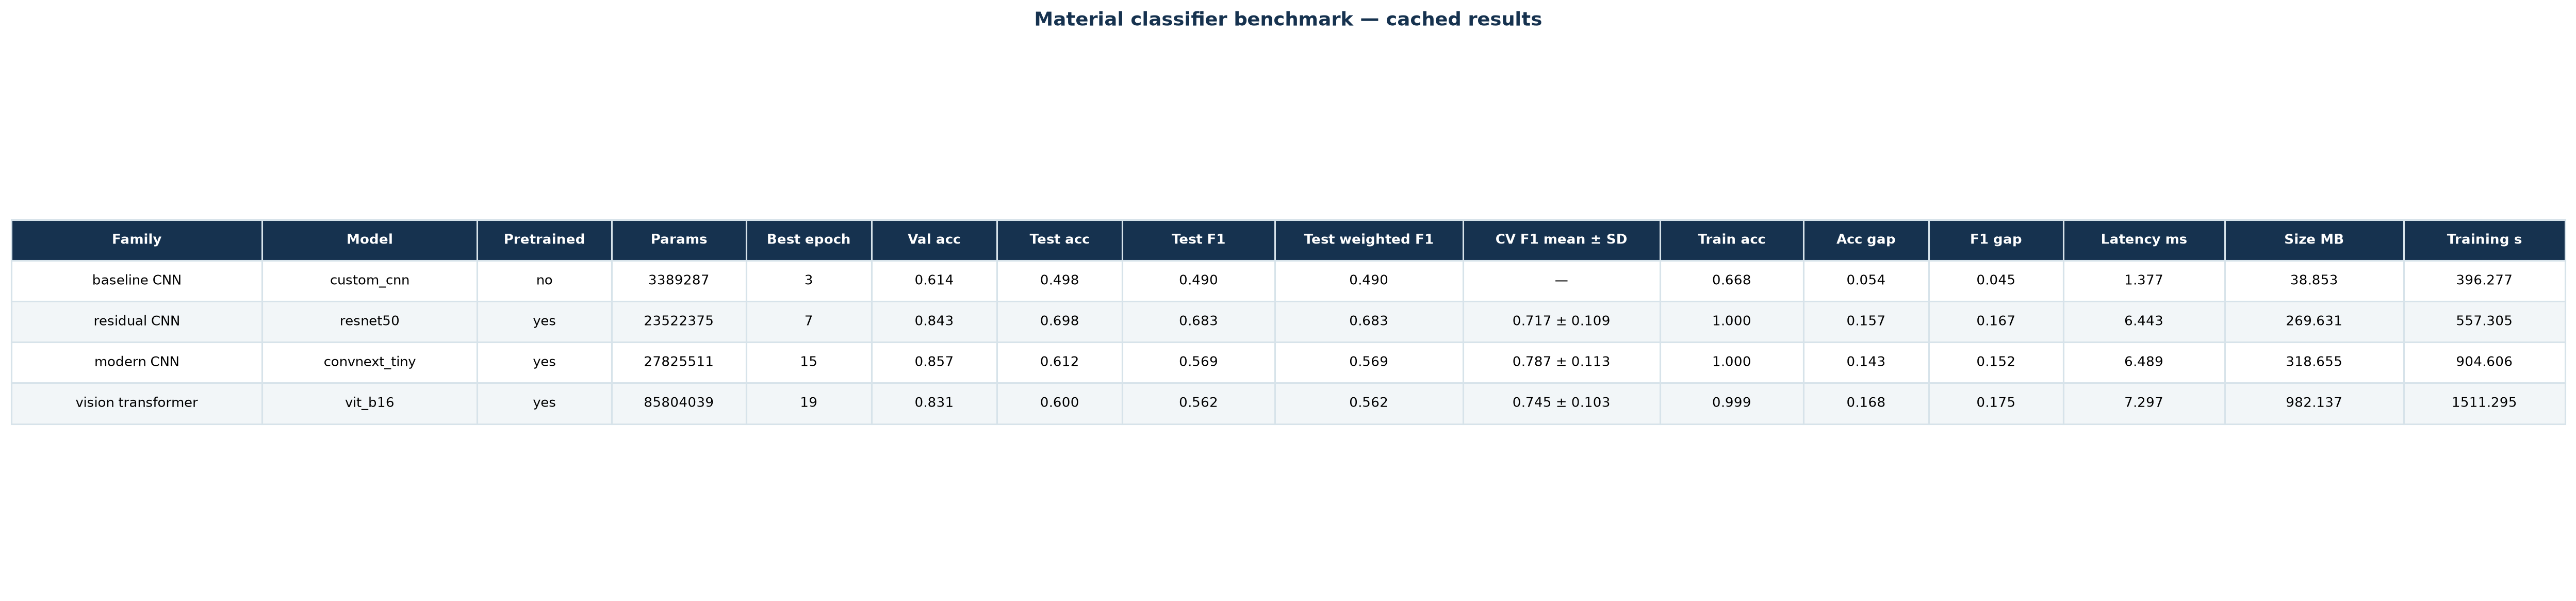

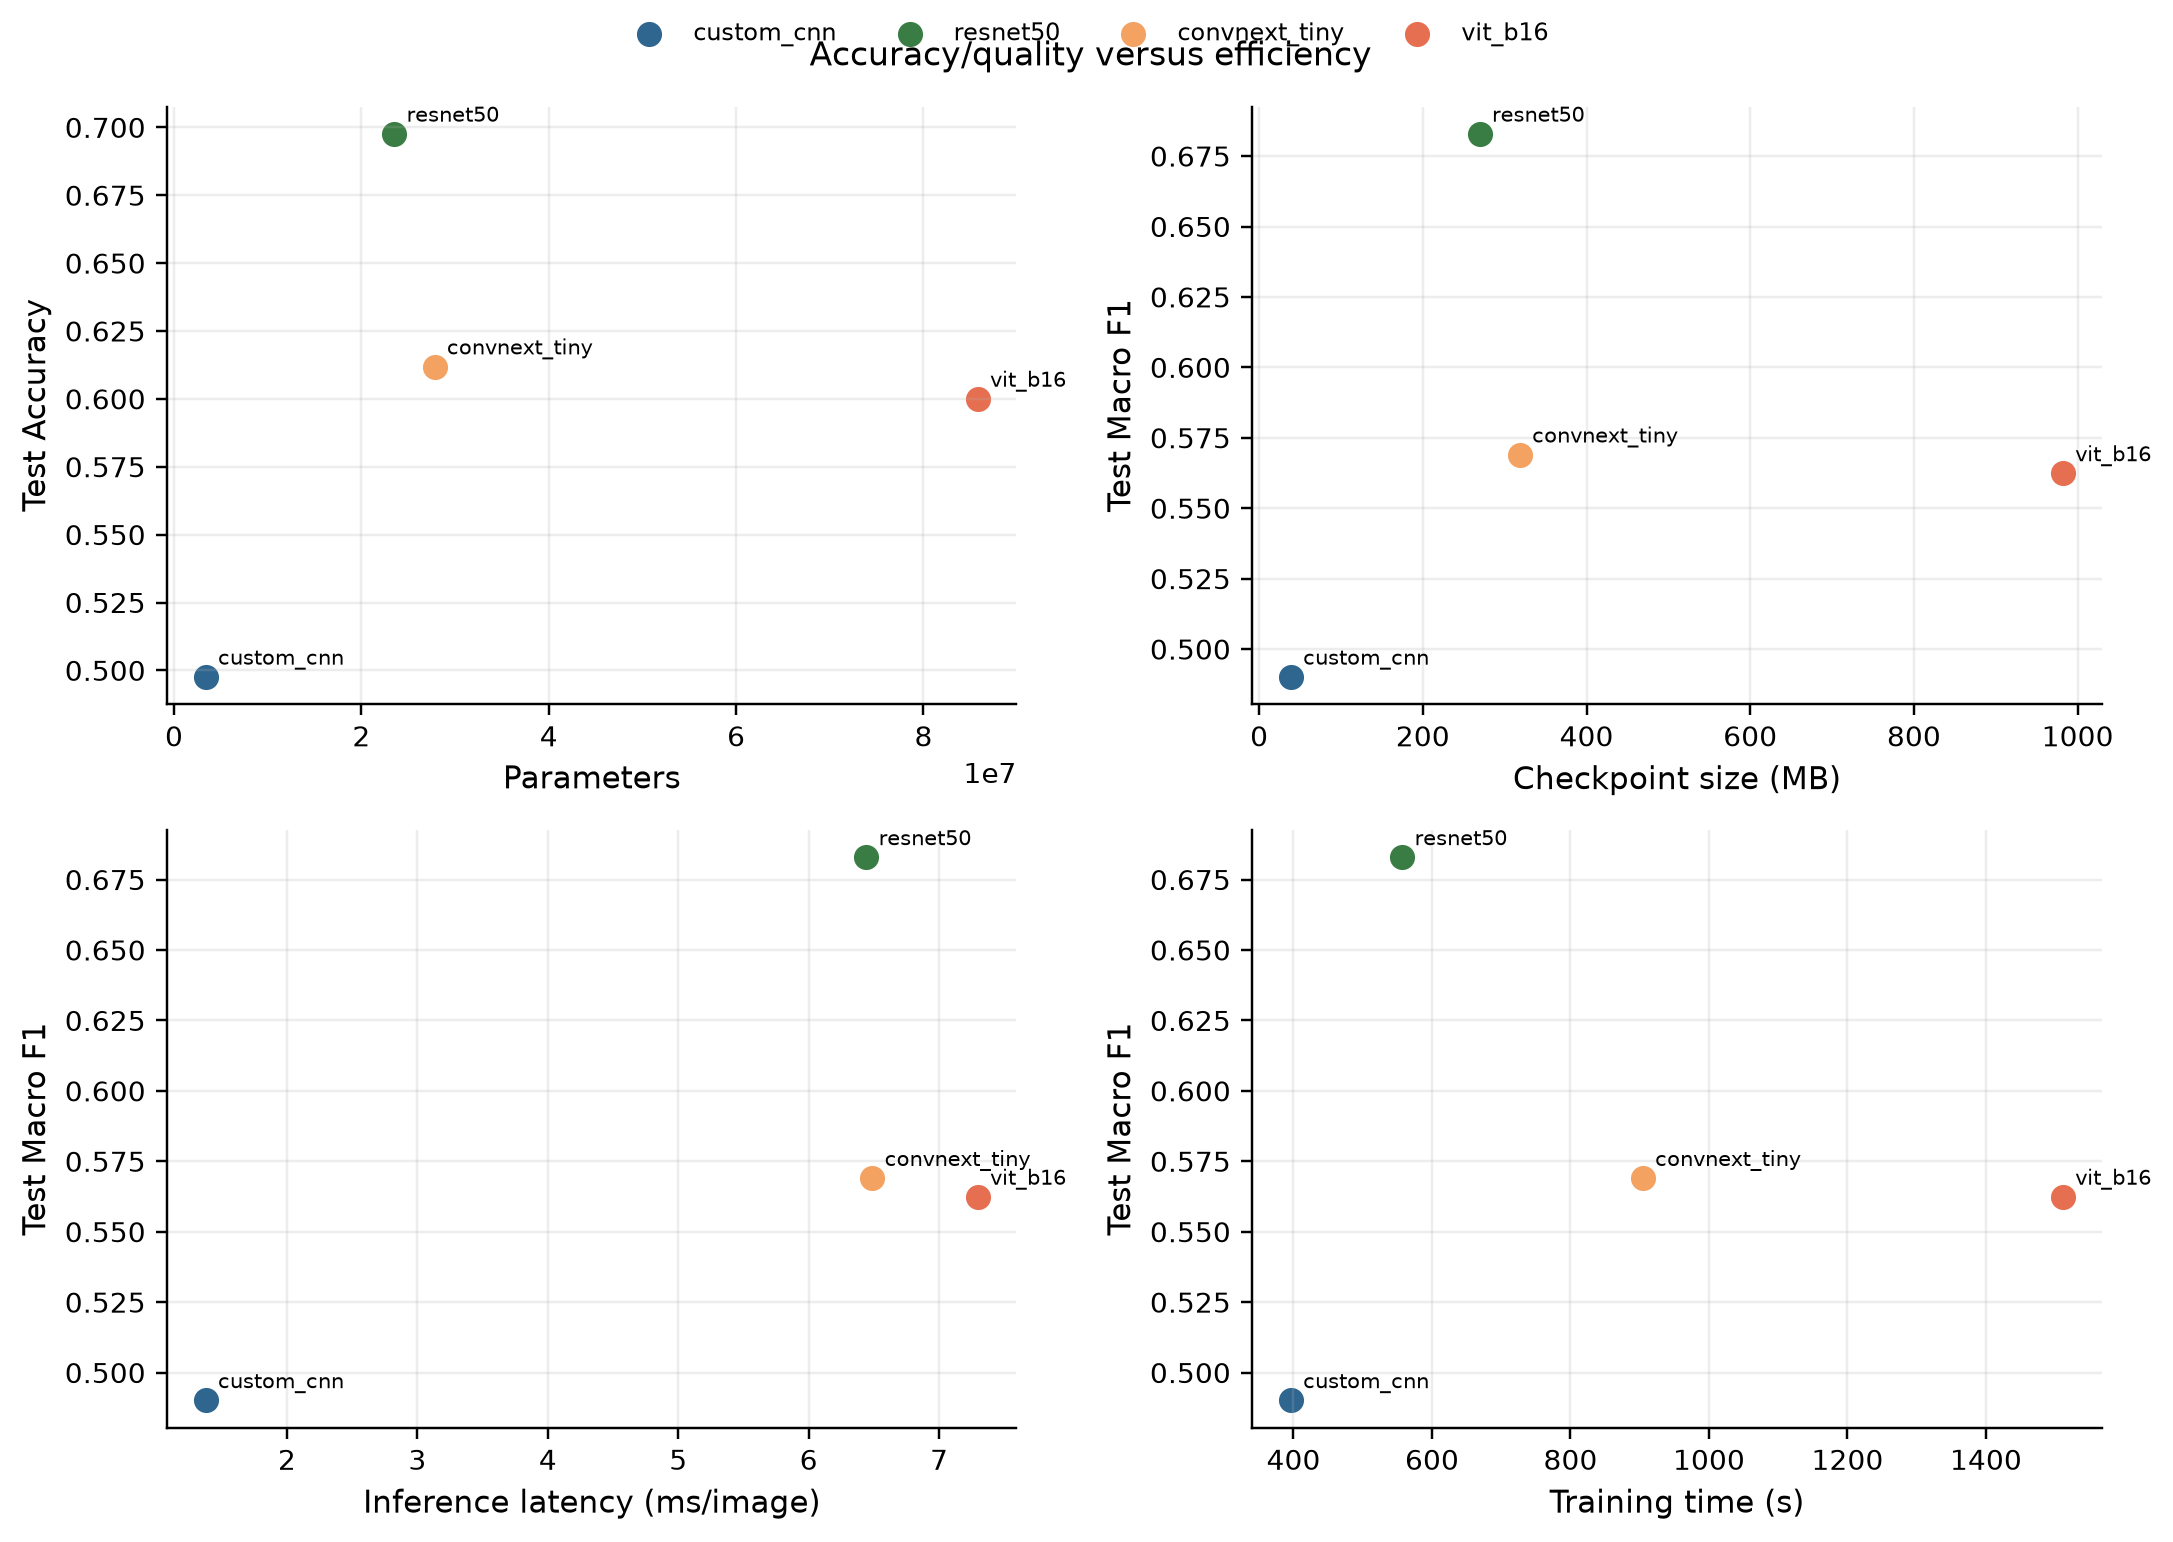

In [2]:
cv_path = ROOT / 'reports' / 'results' / 'cross_validation_results.csv'
if cv_path.exists():
    cv = pd.read_csv(cv_path)
    summary = cv.groupby('model')['f1_macro'].agg(['mean', 'std']).rename(columns={'mean': 'cv_macro_f1_mean', 'std': 'cv_macro_f1_std'})
    display(summary.style.format(precision=3))
else:
    print('Grouped-CV results are pending.')

for path in (ROOT / 'reports' / 'figures' / 'comparison' / 'model_comparison_dashboard.png', ROOT / 'reports' / 'figures' / 'comparison' / 'efficiency_tradeoffs.png'):
    if path.exists(): display(Image(filename=str(path)))